<a href="https://colab.research.google.com/github/Meenakshi-N-24/RedFlag/blob/main/notebooks/01_baseline_tfidf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RedFlag - Day 1: Dataset + Baseline
Goal: load the SMS Spam Collection, inspect it, split it properly, and train a TF-IDF + Logistic Regression baseline.

**Rule:** the test split is touched only once, at the very end of the project. Tune on the validation split.

In [2]:
import pandas as pd, numpy as np, re, zipfile, io, urllib.request, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

## 1. Load the dataset (UCI SMS Spam Collection)

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
raw = urllib.request.urlopen(url).read()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    df = pd.read_csv(z.open("SMSSpamCollection"), sep="\t", names=["label", "text"])

# If the download fails: get the dataset from Kaggle ("SMS Spam Collection Dataset"),
# upload the CSV to Colab, and load it with pd.read_csv(...) instead.
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Inspect: size, class balance, duplicates, message length

In [4]:
print("Rows:", len(df))
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))
print("Duplicate messages:", df.duplicated(subset="text").sum())
df["length"] = df["text"].str.len()
print(df.groupby("label")["length"].describe().round(1))

Rows: 5572
label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64
Duplicate messages: 403
        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4825.0   71.5  58.4   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0


In [5]:
# Remove exact duplicates so the same message can't appear in both train and test
df = df.drop_duplicates(subset="text").reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)   # 1 = spam/scam, 0 = legitimate
print("Rows after dedup:", len(df), "| spam share:", df["y"].mean().round(3))

Rows after dedup: 5169 | spam share: 0.126


## 3. Light cleaning
Keep it light: scam cues like URLs, phone numbers and money amounts are *signals*, so we replace them with tokens instead of deleting them.

In [6]:
def clean(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " urltoken ", t)
    t = re.sub(r"\b\d{10,}\b", " phonetoken ", t)
    t = re.sub(r"[\u20b9$\u00a3]\s?\d[\d,\.]*|\brs\.?\s?\d[\d,\.]*", " moneytoken ", t)
    t = re.sub(r"\d+", " numtoken ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["clean"] = df["text"].apply(clean)
df[["text", "clean"]].sample(5, random_state=1)

,text,clean
2971,Ok. But i finish at 6.,ok. but i finish at numtoken .
3830,87077: Kick off a new season with 2wks FREE go...,numtoken : kick off a new season with numtoken...
3066,Ron say fri leh. N he said ding tai feng cant ...,ron say fri leh. n he said ding tai feng cant ...
3231,Do you want a new Video phone? 600 anytime any...,do you want a new video phone? numtoken anytim...
2139,"I prefer my free days... Tues, wed, fri oso ca...","i prefer my free days... tues, wed, fri oso ca..."


## 4. Split: 70% train / 15% validation / 15% test (stratified)

In [7]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=RANDOM_STATE)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=RANDOM_STATE)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(d), "spam share:", d["y"].mean().round(3))

# Save the splits so every later step (DistilBERT, evaluation) uses the exact same data
train_df.to_csv("train.csv", index=False); val_df.to_csv("val.csv", index=False); test_df.to_csv("test.csv", index=False)

train 3618 spam share: 0.126
val 775 spam share: 0.126
test 776 spam share: 0.126


## 5. Baseline: TF-IDF + Logistic Regression

In [8]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vec.fit_transform(train_df["clean"])   # fit on TRAIN only
X_val   = vec.transform(val_df["clean"])

clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
clf.fit(X_train, train_df["y"])

val_pred = clf.predict(X_val)
print(classification_report(val_df["y"], val_pred, target_names=["legit", "spam"], digits=3))

              precision    recall  f1-score   support

       legit      0.991     0.987     0.989       677
        spam      0.911     0.939     0.925        98

    accuracy                          0.981       775
   macro avg      0.951     0.963     0.957       775
weighted avg      0.981     0.981     0.981       775



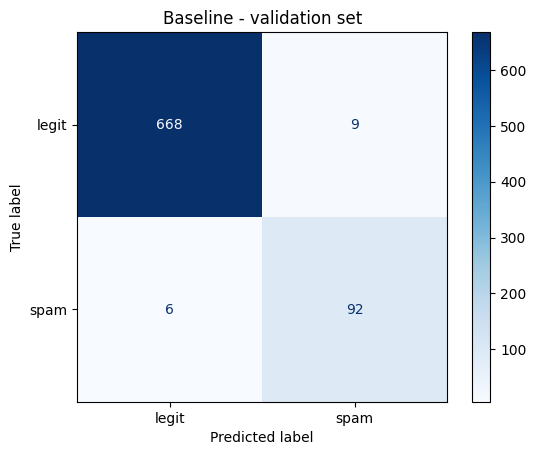

In [9]:
cm = confusion_matrix(val_df["y"], val_pred)
ConfusionMatrixDisplay(cm, display_labels=["legit", "spam"]).plot(cmap="Blues")
plt.title("Baseline - validation set"); plt.show()

## 6. Look at the mistakes
Reading the errors teaches you more than the score does. Note which kinds of messages get missed. This goes in your report.

In [10]:
errors = val_df.assign(pred=val_pred)
errors = errors[errors["y"] != errors["pred"]]
print("False negatives (spam we missed):")
for t in errors[errors["y"] == 1]["text"].head(8): print(" -", t[:150])
print("\nFalse positives (legit flagged as spam):")
for t in errors[errors["y"] == 0]["text"].head(8): print(" -", t[:150])

False negatives (spam we missed):
 - Save money on wedding lingerie at www.bridal.petticoatdreams.co.uk Choose from a superb selection with national delivery. Brought to you by WeddingFri
 - Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
 - Latest News! Police station toilet stolen, cops have nothing to go on!
 - In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
 - Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msg
 - Missed call alert. These numbers called but left no message. 07008009200

False positives (legit flagged as spam):
 - No b4 Thursday
 - 2 and half years i missed your friendship:-)
 - Sir, i am waiting for your call, once free please call me.
 - Is toshiba portege m100 gd?
 - HEY DAS COOL... IKNOW ALL 2 WELLDA PERIL OF STUDENTFINANCIAL CRISI

## 7. Save the baseline

In [11]:
joblib.dump(vec, "tfidf.joblib"); joblib.dump(clf, "baseline_lr.joblib")
print("Saved. Download train.csv, val.csv, test.csv and the .joblib files from the Colab file panel.")

Saved. Download train.csv, val.csv, test.csv and the .joblib files from the Colab file panel.


              precision    recall  f1-score   support

       legit      0.512     0.420     0.462        50
        spam      0.508     0.600     0.550        50

    accuracy                          0.510       100
   macro avg      0.510     0.510     0.506       100
weighted avg      0.510     0.510     0.506       100



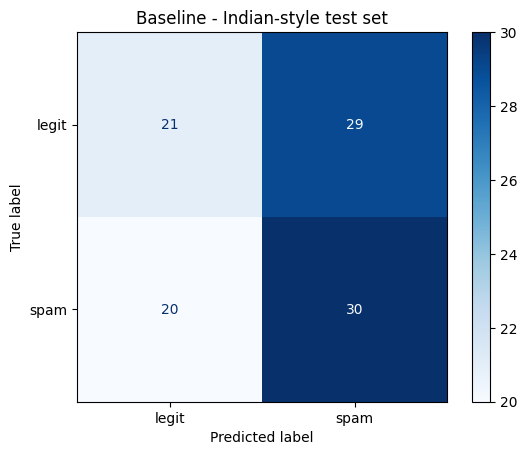

In [12]:
indian = pd.read_csv("indian_test_set.csv")
indian["clean"] = indian["text"].apply(clean)
X_ind = vec.transform(indian["clean"])
ind_pred = clf.predict(X_ind)

print(classification_report(indian["label"], ind_pred, target_names=["legit", "spam"], digits=3))

cm = confusion_matrix(indian["label"], ind_pred)
ConfusionMatrixDisplay(cm, display_labels=["legit", "spam"]).plot(cmap="Blues")
plt.title("Baseline - Indian-style test set"); plt.show()

In [13]:
indian["pred"] = ind_pred
wrong = indian[indian["label"] != indian["pred"]]
print("Scams we MISSED:")
for t in wrong[wrong["label"] == 1]["text"].head(10): print(" -", t[:110])
print("\nLegit messages wrongly FLAGGED:")
for t in wrong[wrong["label"] == 0]["text"].head(10): print(" -", t[:110])

Scams we MISSED:
 - Dear customer, your KYC verification is pending. Kindly confirm your account details at https://fake.example/v
 - Your job application has been shortlisted. Please pay ₹850 for mandatory registration before your interview sl
 - We were unable to deliver your parcel because the address needs confirmation. Pay ₹35 at https://fake.example/
 - Hi, it's me. I've lost my phone and I'm using someone else's number. Please send me money urgently; I'll expla
 - Aapka SIM aaj band ho sakta hai. Verification ke liye turant 9000000003 par call karein.
 - Aapka bank account safe rakhne ke liye, kisi ko bhi OTP mat batayein. Bas verification ke liye apna OTP humein
 - Hello, I am your new relationship manager. Please call me back urgently so I can help you avoid account restri
 - Your electricity connection may be disconnected today. Please reply with your consumer number and confirm the 
 - Aapke naam par reward approve hua hai. Aaj hi YES reply karein aur apni personal details c